# 02 — EDA: Giao hàng & Review
Input: `output/fact_orders_clean.csv`, chỉ dùng các order `in_scope = 1` (delivered, có review, 01/2017–08/2018).

Câu hỏi:
1. Tỉ lệ giao trễ bao nhiêu, ở đâu, khi nào, ngành nào?
2. Giao trễ làm review giảm bao nhiêu?
3. Những yếu tố nào khác đi cùng review xấu?

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

from utils.stats import *
from utils.visual import *

In [2]:
df = pd.read_csv("../output/fact_orders_clean.csv", low_memory=False,
                 parse_dates=["order_purchase_timestamp", "order_delivered_customer_date",
                              "order_estimated_delivery_date"])
df = df[df["in_scope"] == 1].copy()

bucket_order = ["Early >7d", "Early/On time (0-7d)", "Late 1-3d", "Late 4-7d", "Late >7d"]
df["delay_bucket"] = pd.Categorical(df["delay_bucket"], categories=bucket_order, ordered=True)
df.shape

(95560, 54)

In [3]:
kpi = pd.Series({
    "orders"          : len(df),
    "revenue (BRL)"   : df["payment_value"].sum(),
    "late rate"       : df["is_late"].mean(),
    "avg review"      : df["review_score"].mean(),
    "bad review rate" : df["bad_review"].mean(),
    "median delivery days": df["delivery_days"].median(),
})
kpi.round(3)

orders                  9.556000e+04
revenue (BRL)           1.524689e+07
late rate               6.700000e-02
avg review              4.156000e+00
bad review rate         1.280000e-01
median delivery days    1.019800e+01
dtype: float64

## 1. Phân tích đơn biến

In [4]:
describe_all(df[['review_score', 'delivery_days', 'estimated_days', 'delay_days', 'total_price', 'total_freight', 'freight_ratio', 'distance_km', 'n_items']])

=== Numeric ===
       review_score  delivery_days  estimated_days  delay_days  total_price  total_freight  freight_ratio  distance_km   n_items
count      95560.00       95560.00        95560.00    95560.00     95560.00       95560.00       95560.00     95085.00  95560.00
mean           4.16          12.50           23.64      -11.84       136.76          22.76           0.31       600.30      1.14
std            1.28           9.45            8.60       10.02       207.85          21.53           0.31       593.14      0.53
min            1.00           0.53            2.01     -147.00         0.85           0.00           0.00         0.00      1.00
25%            4.00           6.75           18.32      -17.00        45.90          13.83           0.13       185.84      1.00
50%            5.00          10.20           23.21      -12.00        86.00          17.16           0.22       433.78      1.00
75%            5.00          15.62           28.37       -7.00       149.90      

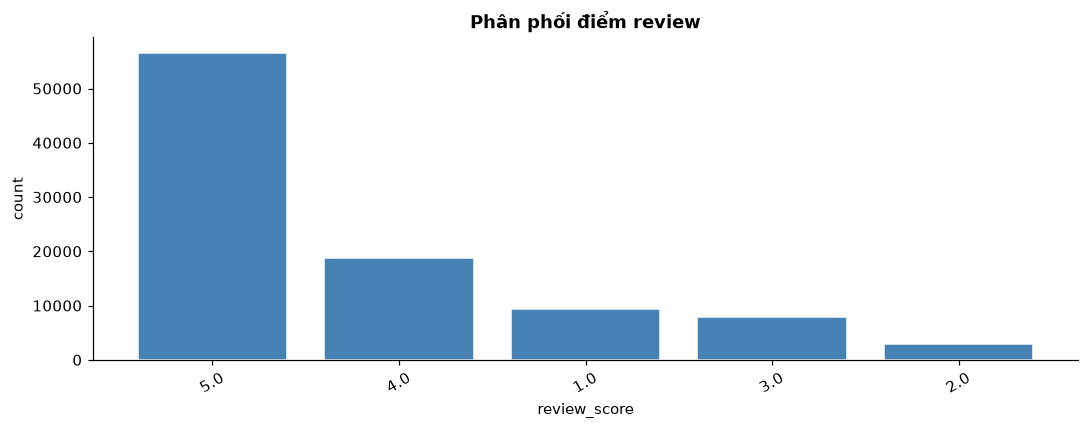

In [5]:
plot_countbar(df, "review_score", title="Phân phối điểm review")

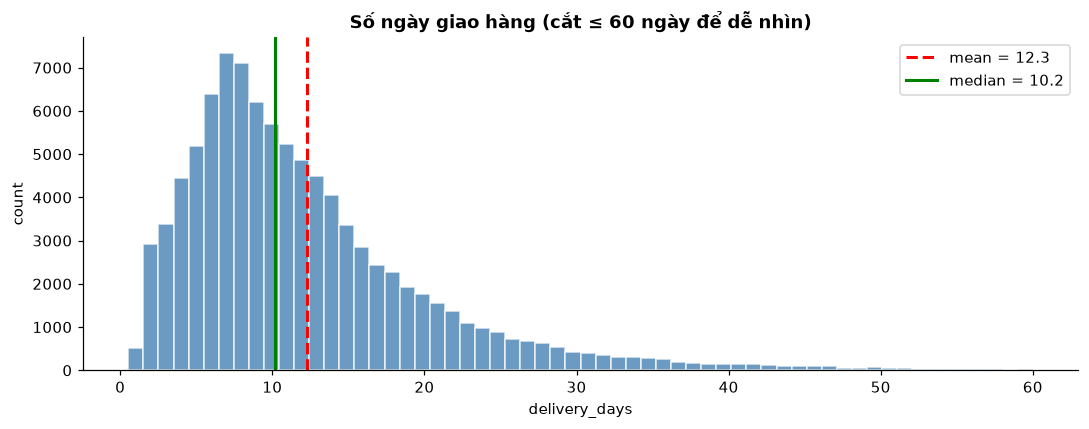

In [6]:
plot_histogram(df[df["delivery_days"] <= 60], "delivery_days", bins=60,
               title="Số ngày giao hàng (cắt ≤ 60 ngày để dễ nhìn)")

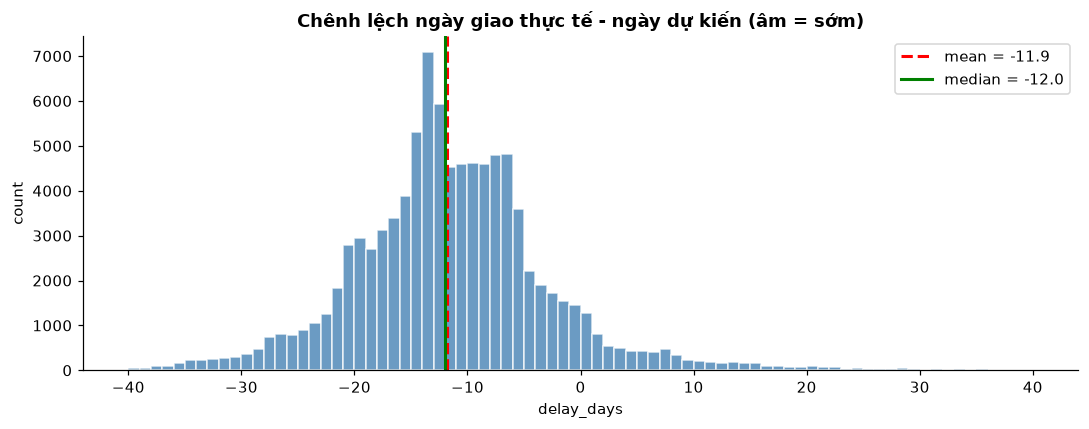

In [7]:
plot_histogram(df[df["delay_days"].between(-40, 40)], "delay_days", bins=80,
               title="Chênh lệch ngày giao thực tế - ngày dự kiến (âm = sớm)")

**Nhận xét**
- Review lệch về 5 sao; review xấu (1–2 sao) chiếm ~13% → bài toán phân loại mất cân bằng.
- Phần lớn đơn giao **sớm** hơn ngày dự kiến (median `delay_days` ≈ −12): Olist đặt ngày dự kiến khá "an toàn".

## 2. Giao trễ → Review

In [8]:
by_bucket = (df.groupby("delay_bucket", observed=True)
                .agg(orders=("order_id", "size"),
                     avg_review=("review_score", "mean"),
                     bad_review_rate=("bad_review", "mean"))
                .assign(share=lambda x: x["orders"] / x["orders"].sum()))
by_bucket.round(3)

,orders,avg_review,bad_review_rate,share
delay_bucket,,,,
Early >7d,70673,4.318,0.090,0.740
Early/On time (0-7d),18509,4.190,0.104,0.194
Late 1-3d,1851,3.291,0.321,0.019
Late 4-7d,1748,2.103,0.677,0.018
Late >7d,2779,1.697,0.793,0.029


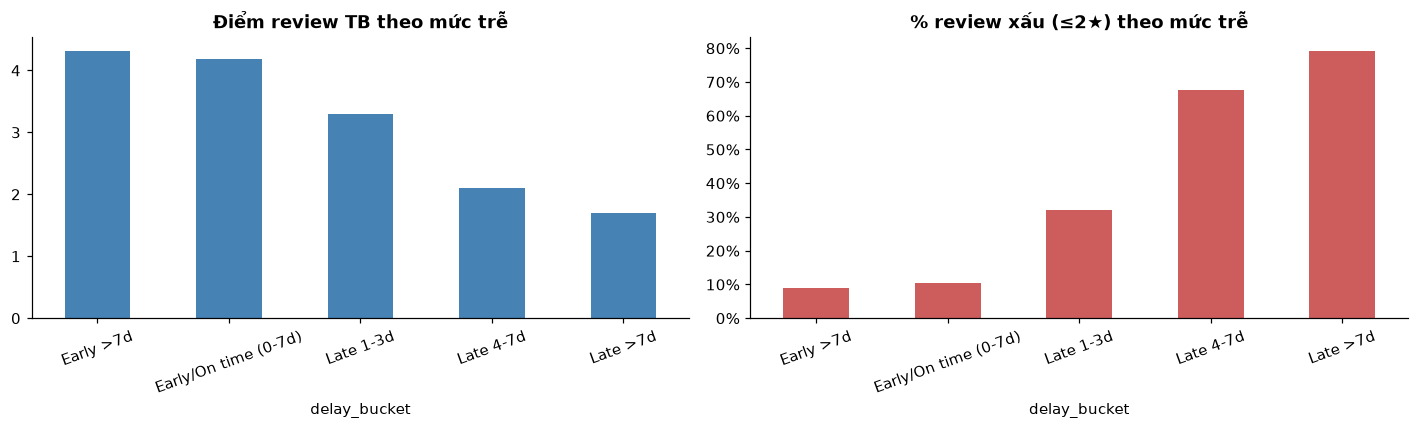

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_bucket["avg_review"].plot(kind="bar", ax=ax[0], color="steelblue", title="Điểm review TB theo mức trễ")
by_bucket["bad_review_rate"].plot(kind="bar", ax=ax[1], color="indianred", title="% review xấu (≤2★) theo mức trễ")
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [10]:
pd.crosstab(df["delay_bucket"], df["review_score"], normalize="index").round(3)

review_score,1.0,2.0,3.0,4.0,5.0
delay_bucket,,,,,
Early >7d,0.065,0.025,0.075,0.199,0.637
Early/On time (0-7d),0.072,0.032,0.102,0.224,0.570
Late 1-3d,0.251,0.070,0.147,0.200,0.332
Late 4-7d,0.586,0.091,0.098,0.084,0.141
Late >7d,0.698,0.095,0.090,0.047,0.070


/Users/doansontung1986/DA05/capstone-project/notebooks/../utils/visual.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=cat_col, y=num_col,


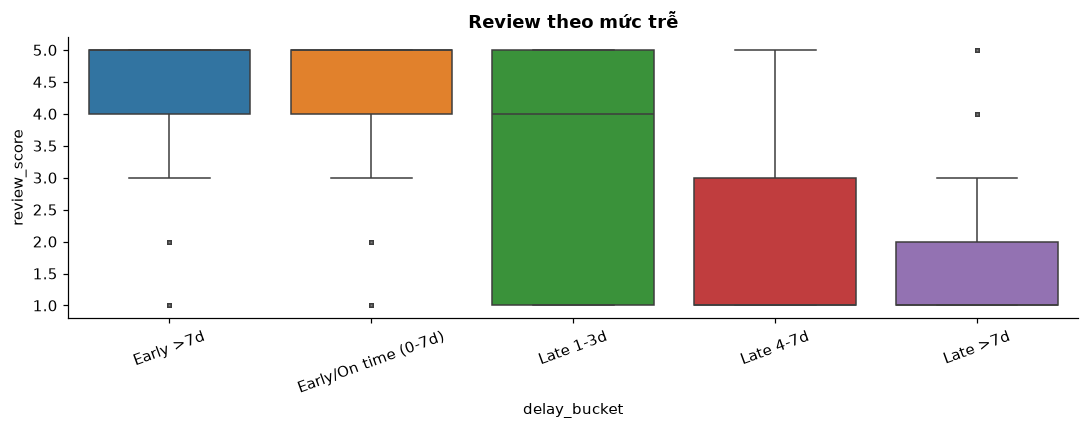

In [11]:
plot_boxplot(df, "review_score", "delay_bucket", title="Review theo mức trễ")

### Kiểm định thống kê

In [12]:
# H0: giao trễ và review xấu độc lập
ct = pd.crosstab(df["is_late"], df["bad_review"])
chi2, p, dof, _ = st.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(ct)
print(f"chi2 = {chi2:,.0f}, p-value = {p:.2e}, Cramér's V = {cramers_v:.3f}")

bad_review    0.0   1.0
is_late                
0.0         80935  8247
1.0          2397  3981
chi2 = 15,075, p-value = 0.00e+00, Cramér's V = 0.397


In [13]:
# Review là thang thứ bậc -> dùng Mann-Whitney U (không giả định phân phối chuẩn)
late, on_time = df.loc[df["is_late"] == 1, "review_score"], df.loc[df["is_late"] == 0, "review_score"]
u, p = st.mannwhitneyu(late, on_time, alternative="less")
print(f"avg review late = {late.mean():.2f}, on time = {on_time.mean():.2f}")
print(f"Mann-Whitney U = {u:,.0f}, p-value = {p:.2e}")

avg review late = 2.27, on time = 4.29
Mann-Whitney U = 102,901,002, p-value = 0.00e+00


**Insight**
- Đơn giao trễ có điểm review trung bình **≈2,3★** so với **≈4,3★** của đơn đúng hạn/sớm.
- % review xấu tăng gần như tuyến tính theo mức trễ: ~10% (đúng hạn) → ~32% (trễ 1–3 ngày) → ~68% (4–7 ngày) → ~79% (>7 ngày).
- Cả chi-square và Mann-Whitney đều có p-value ≈ 0 → khác biệt có ý nghĩa thống kê (lưu ý: đây là **tương quan**, không phải bằng chứng nhân quả).

## 3. Giao trễ ở đâu?

In [14]:
by_state = (df.groupby("customer_state")
               .agg(orders=("order_id", "size"),
                    late_rate=("is_late", "mean"),
                    avg_delivery_days=("delivery_days", "mean"),
                    avg_review=("review_score", "mean"))
               .sort_values("late_rate", ascending=False))
by_state.round(3)

,orders,late_rate,avg_delivery_days,avg_review
customer_state,,,,
AL,393,0.209,24.435,3.847
MA,709,0.172,21.464,3.829
SE,331,0.151,21.357,3.900
PI,470,0.138,19.478,3.994
CE,1267,0.137,21.177,3.940
RR,40,0.125,29.908,3.900
RJ,12172,0.120,15.229,3.965
BA,3226,0.119,19.244,3.930
PA,929,0.108,23.625,3.913


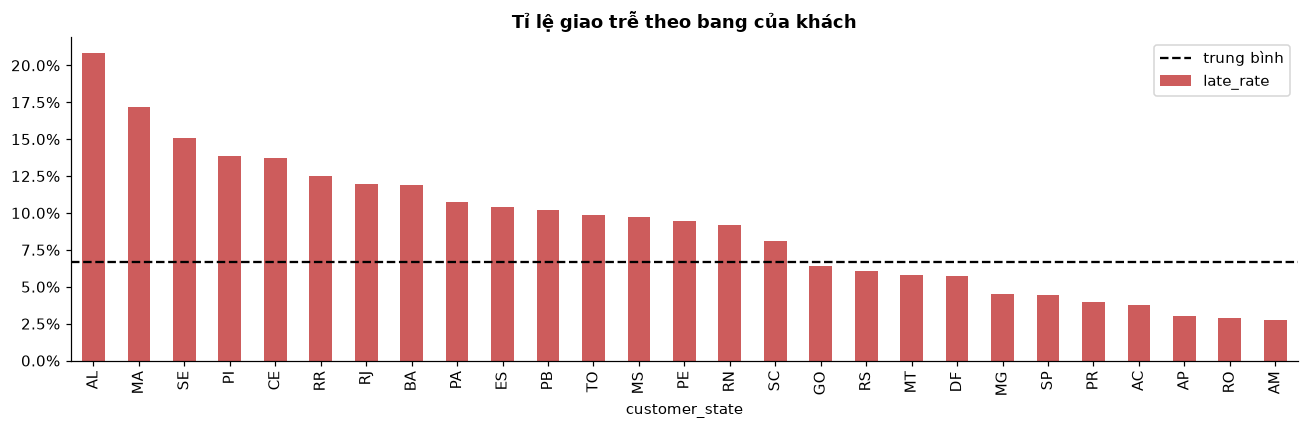

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
by_state["late_rate"].plot(kind="bar", ax=ax, color="indianred", title="Tỉ lệ giao trễ theo bang của khách")
ax.axhline(df["is_late"].mean(), color="black", ls="--", label="trung bình")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(); plt.tight_layout(); plt.show()

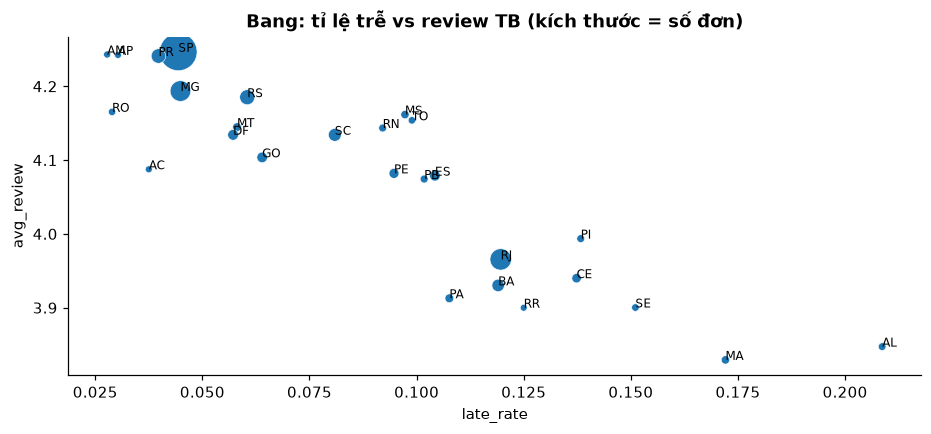

In [16]:
sns.scatterplot(data=by_state.reset_index(), x="late_rate", y="avg_review", size="orders", sizes=(20, 600), legend=False)
for s, r in by_state.iterrows():
    plt.annotate(s, (r["late_rate"], r["avg_review"]), fontsize=8)
plt.title("Bang: tỉ lệ trễ vs review TB (kích thước = số đơn)"); plt.show()

In [17]:
# Tuyến seller -> customer phổ biến nhất có tỉ lệ trễ cao
routes = (df.groupby(["seller_state", "customer_state"])
            .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                 avg_review=("review_score", "mean"))
            .query("orders >= 300")
            .sort_values("late_rate", ascending=False))
routes.head(10).round(3)

orders  late_rate  avg_review
seller_state customer_state                               
SP           MA                 486      0.187       3.708
             PI                 324      0.164       3.960
             RJ                8047      0.140       3.887
             CE                 961      0.136       3.963
             BA                2288      0.127       3.871
             MS                 476      0.124       4.090
             ES                1443      0.121       4.052
PR           RJ                 954      0.117       3.899
SP           PA                 671      0.116       3.872
             PB                 332      0.102       4.033

In [18]:
df["distance_bin"] = pd.cut(df["distance_km"], [0, 100, 300, 600, 1000, 2000, np.inf],
                            labels=["<100", "100-300", "300-600", "600-1000", "1000-2000", ">2000"],
                            include_lowest=True)
(df.groupby("distance_bin", observed=True)
   .agg(orders=("order_id", "size"), avg_delivery_days=("delivery_days", "mean"),
        late_rate=("is_late", "mean"), bad_review_rate=("bad_review", "mean"))
   .round(3))

,orders,avg_delivery_days,late_rate,bad_review_rate
distance_bin,,,,
<100,17743,6.466,0.044,0.104
100-300,13228,9.959,0.051,0.107
300-600,31193,12.552,0.066,0.134
600-1000,17734,14.660,0.070,0.133
1000-2000,9649,17.900,0.093,0.148
>2000,5538,21.082,0.119,0.168


## 4. Khi nào trễ?

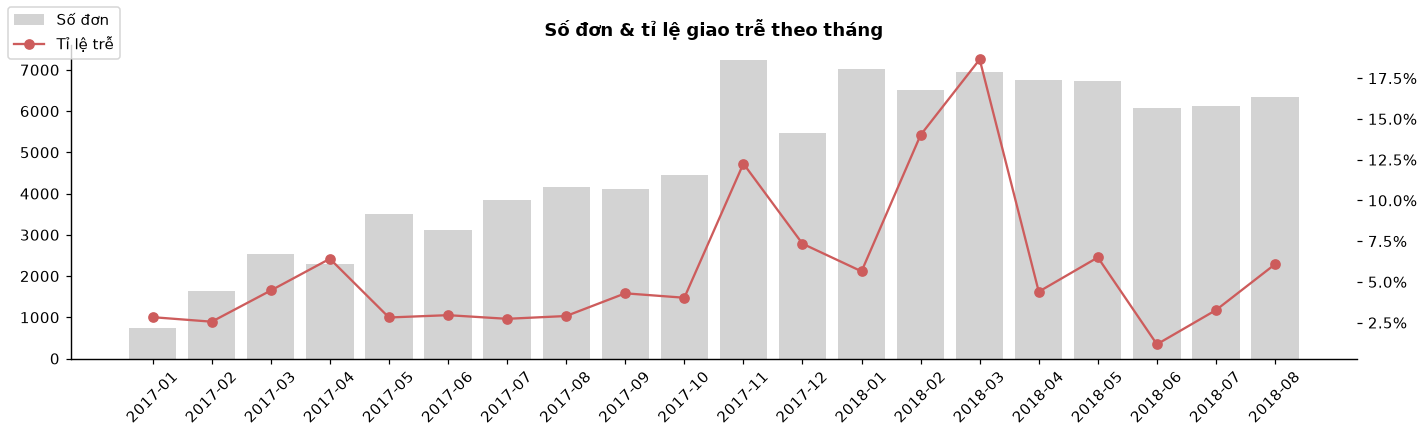

In [19]:
by_month = (df.groupby("year_month")
               .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                    avg_review=("review_score", "mean")))
fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.bar(by_month.index, by_month["orders"], color="lightgray", label="Số đơn")
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month["late_rate"], color="indianred", marker="o", label="Tỉ lệ trễ")
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax1.tick_params(axis="x", rotation=45)
ax1.set_title("Số đơn & tỉ lệ giao trễ theo tháng")
fig.legend(loc="upper left"); plt.tight_layout(); plt.show()

In [20]:
by_month.round(3)

,orders,late_rate,avg_review
year_month,,,
2017-01,741,0.028,4.198
2017-02,1643,0.026,4.203
2017-03,2527,0.045,4.187
2017-04,2290,0.064,4.135
2017-05,3517,0.028,4.236
2017-06,3111,0.030,4.223
2017-07,3842,0.027,4.260
2017-08,4165,0.029,4.313
2017-09,4118,0.043,4.268


**Insight:** Tỉ lệ trễ tăng vọt vào **11/2017** (Black Friday, số đơn tăng mạnh) và **02–03/2018**, trong khi các tháng khác thường dưới ~7%. → Năng lực vận chuyển không theo kịp các đợt cao điểm.

## 5. Ngành hàng

In [21]:
by_cat = (df.groupby("main_category")
             .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                  avg_review=("review_score", "mean"), bad_review_rate=("bad_review", "mean"),
                  revenue=("payment_value", "sum"))
             .query("orders >= 500")
             .sort_values("bad_review_rate", ascending=False))
by_cat.round(3)

,orders,late_rate,avg_review,bad_review_rate,revenue
main_category,,,,,
office_furniture,1236,0.080,3.655,0.217,331376.679
unknown,1347,0.071,4.039,0.166,197239.310
bed_bath_table,9086,0.073,4.007,0.158,1214200.181
furniture_decor,6095,0.072,4.080,0.148,862604.621
computers_accessories,6468,0.063,4.084,0.145,1027247.540
telephony,4042,0.071,4.059,0.139,375925.000
baby,2730,0.080,4.122,0.137,462663.800
watches_gifts,5432,0.073,4.122,0.137,1254997.329
electronics,2482,0.077,4.129,0.131,196360.590


## 6. Các yếu tố khác

In [22]:
(df.groupby("n_sellers").agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                             bad_review_rate=("bad_review", "mean")).round(3))

,orders,late_rate,bad_review_rate
n_sellers,,,
1.0,94302,0.068,0.123
2.0,1199,0.010,0.463
3.0,54,0.000,0.611
4.0,3,0.000,1.000
5.0,2,0.000,1.000


In [23]:
df["n_items_bin"] = pd.cut(df["n_items"], [0, 1, 2, 3, np.inf], labels=["1", "2", "3", "4+"])
(df.groupby("n_items_bin", observed=True).agg(orders=("order_id", "size"),
                                              bad_review_rate=("bad_review", "mean")).round(3))

,orders,bad_review_rate
n_items_bin,,
1,86061,0.113
2,7300,0.254
3,1281,0.290
4+,918,0.341


In [24]:
df["freight_ratio_bin"] = pd.qcut(df["freight_ratio"], 5)
(df.groupby("freight_ratio_bin", observed=True).agg(orders=("order_id", "size"),
                                                    bad_review_rate=("bad_review", "mean")).round(3))

,orders,bad_review_rate
freight_ratio_bin,,
"(-0.001, 0.115]",19112,0.123
"(0.115, 0.183]",19112,0.123
"(0.183, 0.274]",19112,0.123
"(0.274, 0.435]",19122,0.135
"(0.435, 21.447]",19102,0.135


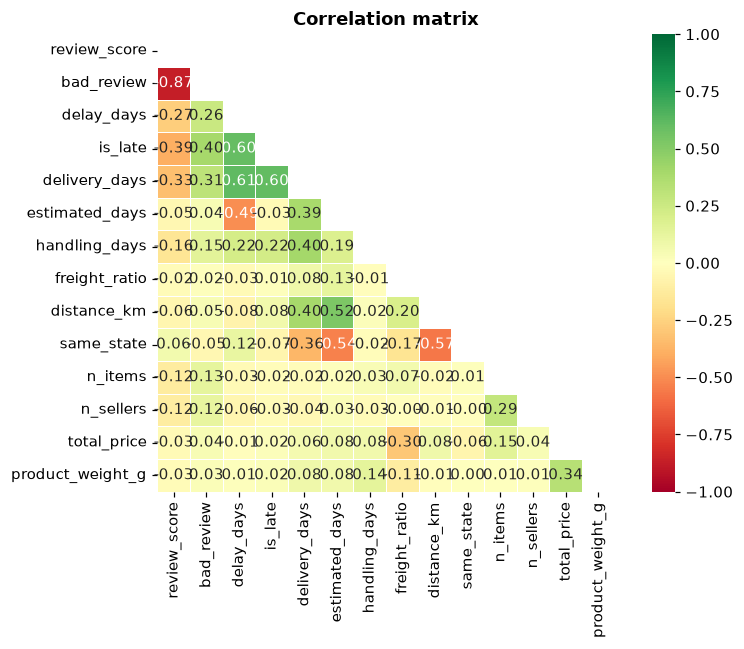

In [25]:
corr_cols = ["review_score", "bad_review", "delay_days", "is_late", "delivery_days", "estimated_days",
             "handling_days", "freight_ratio", "distance_km", "same_state", "n_items", "n_sellers",
             "total_price", "product_weight_g"]
plot_heatmap_corr(df, corr_cols)

**Insight**
- Đơn có **≥2 người bán**: % review xấu ~46% (so với ~12% đơn 1 người bán) **dù tỉ lệ trễ chỉ ~1%** → review xấu ở nhóm này *không* giải thích được bằng giao trễ. Giả thuyết (chưa kiểm chứng được bằng dữ liệu này): hàng về thành nhiều kiện, ngày giao ghi nhận không phản ánh kiện cuối, hoặc thiếu hàng.
- Số item càng nhiều, % review xấu càng tăng (11% → 34%).
- Khoảng cách: >2000 km có tỉ lệ trễ ~12% vs ~4% (<100 km).
- Phí ship (`freight_ratio`) gần như không khác biệt về % review xấu giữa các nhóm (12–13%).
- `is_late`, `delivery_days`, `delay_days` là các biến tương quan mạnh nhất với review; `freight_ratio`, `distance_km` tương quan rất yếu.

→ Các biến này là input cho mô hình What-if (notebook 03).

In [26]:
# Lưu bảng tổng hợp cho báo cáo / LLM reasoning
by_bucket.to_csv("../output/eda_by_delay_bucket.csv")
by_state.to_csv("../output/eda_by_state.csv")
by_month.to_csv("../output/eda_by_month.csv")
by_cat.to_csv("../output/eda_by_category.csv")